# Green Light Analytics: SQL queries -> charts

Each section runs one of our SQL queries with `pd.read_sql`, then draws the chart for the slide. The queries run on the 8 table CSVs from `imdb_build_tables.ipynb`, loaded into a small SQLite database in memory, so the notebook needs no MySQL connection and no password. The SQL is the same as in our MySQL query file.

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

# No MySQL connection needed: load our 8 table CSVs into a small database inside Python
# (sqlite3 comes with Python, nothing to install, no password).
# The same SQL queries we wrote for MySQL run on it unchanged.
tables_dir = "../data/clean"
table_names = ["directors", "actors", "genres", "certificates",
               "movies", "movie_genres", "movie_cast", "ratings"]

engine = sqlite3.connect(":memory:")
for name in table_names:
    pd.read_csv(f"{tables_dir}/{name}.csv").to_sql(name, engine, index=False)
    print("loaded", name)

# chart style: green to match the "Market Research Classic" slides
# (to match the template exactly: in Google Slides open Slide > Edit theme > Colours, copy the hex codes here)
BLUE = "#9fd3b0"        # normal bars (light green); the name is kept so the rest of the code stays the same
HIGHLIGHT = "#1f7a4d"   # the bar we talk about (dark green)
TEXT = "#52514e"

plt.rcParams.update({
    "figure.figsize": (9, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TEXT, "xtick.color": TEXT,
    "ytick.color": TEXT, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

import os
os.makedirs("slide_charts", exist_ok=True)

def save_chart(title):
    """Save the current chart as a PNG in the slide_charts folder (file name = chart title)."""
    name = title.replace(" ", "_").replace("/", "-").replace(":", "").replace("(", "").replace(")", "")
    plt.savefig(f"slide_charts/{name}.png", dpi=200, bbox_inches="tight")

def hbar(data, label_col, value_col, title, xlabel, fmt="{:,.0f}"):
    """Horizontal bar chart, biggest on top, top bar highlighted, value at the end of each bar."""
    data = data.sort_values(value_col)
    colors = [HIGHLIGHT if v == data[value_col].max() else BLUE for v in data[value_col]]
    fig, ax = plt.subplots()
    bars = ax.barh(data[label_col], data[value_col], color=colors, height=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in data[value_col]], padding=4, color=TEXT, fontsize=9)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    plt.tight_layout()
    save_chart(title)
    plt.show()

def dotplot(data, label_col, value_col, title, xlabel, fmt="{:.2f}"):
    """Lollipop / dot chart: a thin line and a dot per row. The axis starts near the lowest value,
    so small differences (like 8.4 vs 8.6) are easy to see. Biggest value highlighted."""
    if data.empty:
        print("No rows to plot: check the query")
        return
    data = data.sort_values(value_col)
    lo = data[value_col].min() - 0.15
    hi = data[value_col].max() + 0.1
    colors = [HIGHLIGHT if v == data[value_col].max() else BLUE for v in data[value_col]]
    fig, ax = plt.subplots()
    ax.hlines(data[label_col], lo, data[value_col], color="#c3c2b7", linewidth=2)
    ax.scatter(data[value_col], data[label_col], s=110, color=colors, zorder=3, edgecolor="white", linewidth=1.5)
    for y, v in zip(data[label_col], data[value_col]):
        ax.text(v + 0.02, y, fmt.format(v), va="center", color=TEXT, fontsize=9)
    ax.set_xlim(lo, hi)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    save_chart(title)
    plt.show()

loaded directors
loaded actors
loaded genres
loaded certificates
loaded movies
loaded movie_genres
loaded movie_cast
loaded ratings


## Q1. Genres: most top-rated films and highest box office

Top-rated = IMDb rating >= 8.5. The temporary table is replaced by a `WITH` (CTE), because `pd.read_sql` runs one statement at a time.

In [2]:
q1 = """
WITH genre_stats AS (
    SELECT g.genre_name,
           COUNT(*)                         AS films,
           SUM(r.imdb_rating >= 8.5)        AS top_rated_films,
           SUM(m.gross_revenue)             AS total_gross,
           AVG(m.gross_revenue)             AS avg_gross
    FROM genres g
    JOIN movie_genres mg ON g.genre_id = mg.genre_id
    JOIN movies m        ON mg.movie_id = m.movie_id
    JOIN ratings r       ON m.movie_id = r.movie_id
    GROUP BY g.genre_id, g.genre_name
)
SELECT * FROM genre_stats
"""
genre_stats = pd.read_sql(q1, engine)
genre_stats["total_gross_m"] = genre_stats["total_gross"] / 1_000_000
genre_stats["avg_gross_m"] = genre_stats["avg_gross"] / 1_000_000
genre_stats.sort_values("top_rated_films", ascending=False).head(10)

,genre_name,films,top_rated_films,total_gross,avg_gross,total_gross_m,avg_gross_m
6,Drama,724,42,2.749762e+10,4.605967e+07,27497.622629,46.059669
5,Crime,209,14,6.956304e+09,4.068014e+07,6956.303927,40.680140
0,Action,189,13,2.203333e+10,1.412393e+08,22033.328131,141.239283
1,Adventure,196,12,2.817432e+10,1.657313e+08,28174.317369,165.731279
4,Comedy,233,6,1.224793e+10,6.412530e+07,12247.931579,64.125296
18,Thriller,137,6,6.454429e+09,5.867663e+07,6454.428931,58.676627
16,Sci-Fi,67,6,9.029610e+09,1.480264e+08,9029.610220,148.026397
14,Mystery,99,5,3.467048e+09,4.127438e+07,3467.048100,41.274382
3,Biography,109,5,5.304578e+09,5.525602e+07,5304.577796,55.256019
15,Romance,125,5,4.318397e+09,4.035885e+07,4318.396644,40.358847


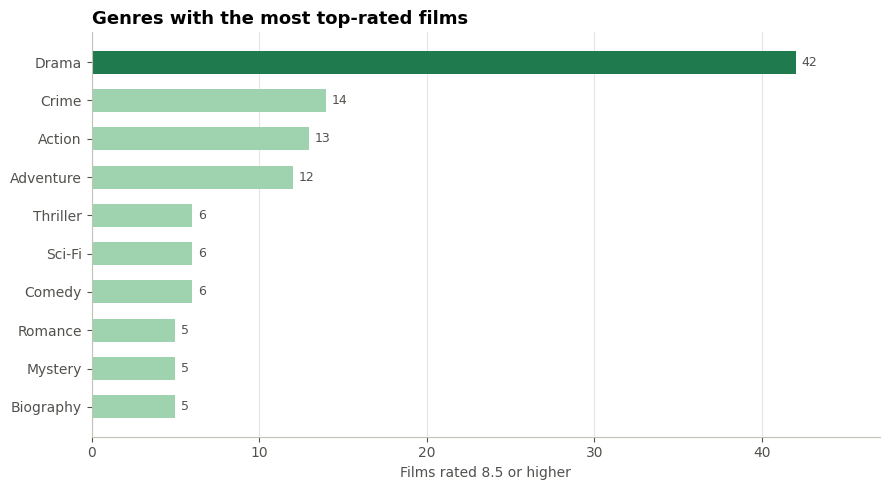

In [3]:
hbar(genre_stats.nlargest(10, "top_rated_films"), "genre_name", "top_rated_films",
     "Genres with the most top-rated films", "Films rated 8.5 or higher")

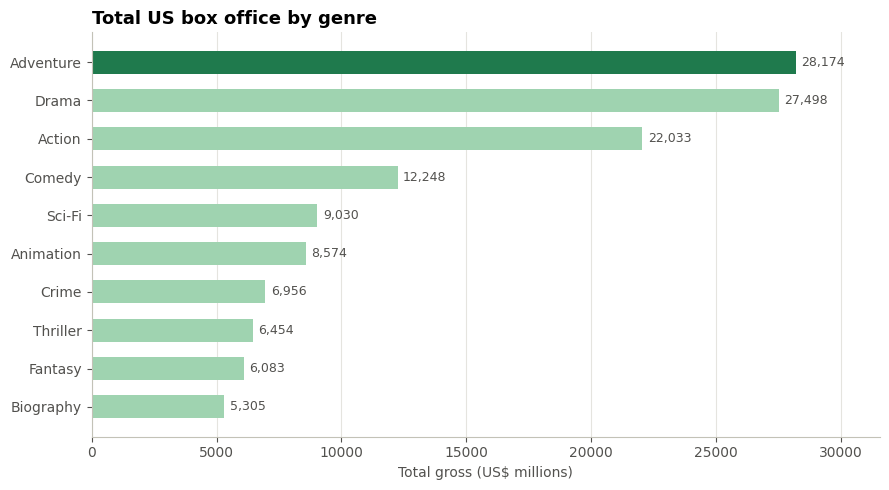

In [4]:
hbar(genre_stats.nlargest(10, "total_gross_m"), "genre_name", "total_gross_m",
     "Total US box office by genre", "Total gross (US$ millions)")

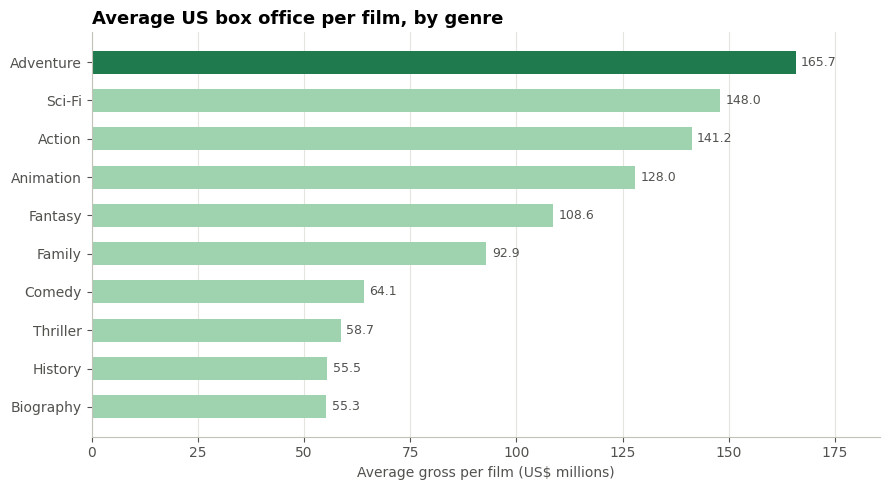

In [5]:
# Fairer comparison: average gross per film (big genres don't win just by having more films)
hbar(genre_stats[genre_stats["films"] >= 20].nlargest(10, "avg_gross_m"), "genre_name", "avg_gross_m",
     "Average US box office per film, by genre", "Average gross per film (US$ millions)", fmt="{:,.1f}")

## Q2. Do critics (meta_score) and audiences (imdb_rating) agree?

Only the 843 films with a real Meta_score are used. IMDb rating is multiplied by 10 so both scores are out of 100.

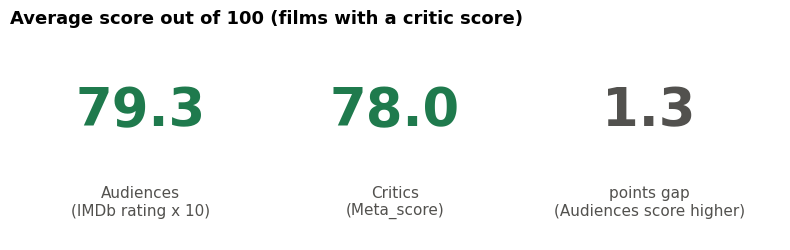

In [6]:
q2_avg = """
SELECT ROUND(AVG(imdb_rating * 10), 1) AS avg_audience_score,
       ROUND(AVG(meta_score), 1)       AS avg_critic_score
FROM ratings
WHERE meta_score IS NOT NULL
"""
avg_scores = pd.read_sql(q2_avg, engine)

# Only two numbers, so show them as two big "score cards" instead of a chart
audience = avg_scores["avg_audience_score"][0]
critics = avg_scores["avg_critic_score"][0]
gap = abs(audience - critics)
higher = "Audiences" if audience > critics else "Critics"

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.axis("off")
for x, value, label, color in [(0.17, audience, "Audiences\n(IMDb rating x 10)", HIGHLIGHT),
                               (0.50, critics, "Critics\n(Meta_score)", HIGHLIGHT)]:
    ax.text(x, 0.62, f"{value:.1f}", ha="center", va="center", fontsize=38, fontweight="bold", color=color)
    ax.text(x, 0.18, label, ha="center", va="center", fontsize=11, color=TEXT)
ax.text(0.83, 0.62, f"{gap:.1f}", ha="center", va="center", fontsize=38, fontweight="bold", color=TEXT)
ax.text(0.83, 0.18, f"points gap\n({higher} score higher)", ha="center", va="center", fontsize=11, color=TEXT)
ax.set_title("Average score out of 100 (films with a critic score)", loc="left")
plt.tight_layout()
save_chart("Average score out of 100")
plt.show()

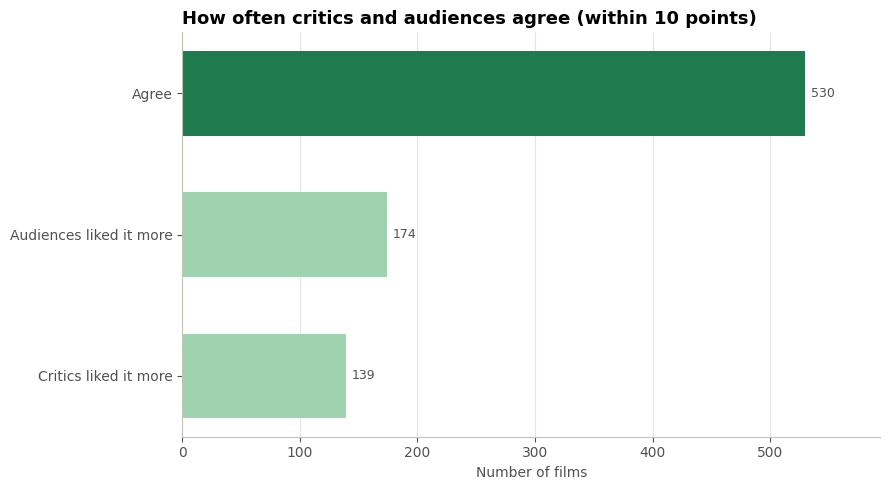

In [7]:
q2_agree = """
SELECT CASE
         WHEN ABS(meta_score - imdb_rating * 10) <= 10 THEN 'Agree'
         WHEN meta_score > imdb_rating * 10           THEN 'Critics liked it more'
         ELSE 'Audiences liked it more'
       END AS opinion,
       COUNT(*) AS films
FROM ratings
WHERE meta_score IS NOT NULL
GROUP BY opinion
"""
agree = pd.read_sql(q2_agree, engine)
hbar(agree, "opinion", "films", "How often critics and audiences agree (within 10 points)", "Number of films")

In [8]:
q2_disagree = """
SELECT m.movie_title,
       ROUND(r.imdb_rating * 10, 2) AS audience_score,
       r.meta_score                 AS critic_score,
       ABS(r.meta_score - r.imdb_rating * 10) AS gap
FROM movies m
JOIN ratings r ON m.movie_id = r.movie_id
WHERE r.meta_score IS NOT NULL
ORDER BY gap DESC
LIMIT 10
"""
pd.read_sql(q2_disagree, engine)   # show as a table on the slide

,movie_title,audience_score,critic_score,gap
0,I Am Sam,77.0,28.0,49.0
1,Tropa de Elite,80.0,33.0,47.0
2,The Butterfly Effect,76.0,30.0,46.0
3,Seven Pounds,76.0,36.0,40.0
4,Kai po che!,77.0,40.0,37.0
5,Fear and Loathing in Las Vegas,76.0,41.0,35.0
6,Pink Floyd: The Wall,81.0,47.0,34.0
7,The Boondock Saints,78.0,44.0,34.0
8,Bound by Honor,80.0,47.0,33.0
9,Predator,78.0,45.0,33.0


## Q3. Talent: directors and actors with consistently high ratings (at least 4 films)

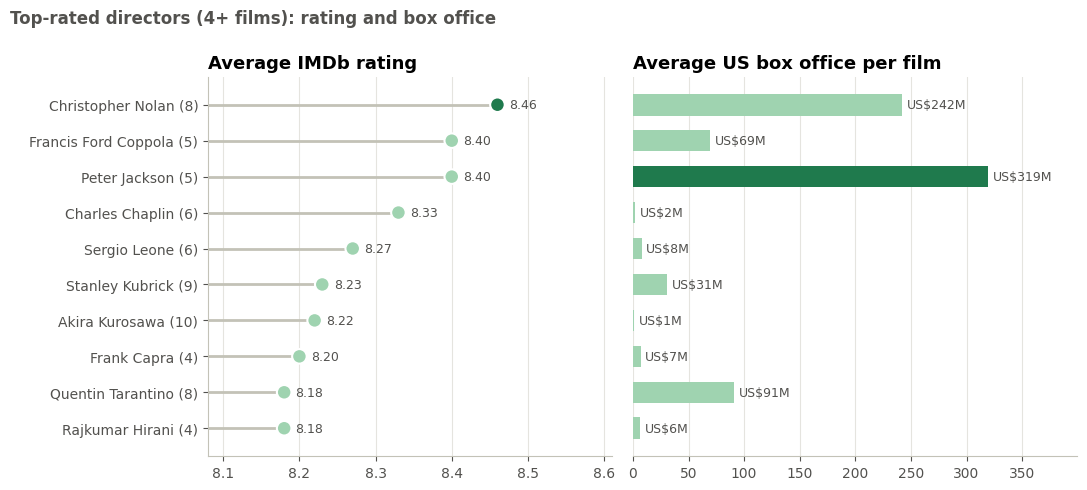

In [9]:
q3_directors = """
SELECT d.director_name,
       COUNT(*)                     AS films,
       ROUND(AVG(r.imdb_rating), 2) AS avg_rating,
       ROUND(AVG(m.gross_revenue))  AS avg_gross
FROM directors d
JOIN movies m  ON d.director_id = m.director_id
JOIN ratings r ON m.movie_id = r.movie_id
GROUP BY d.director_id, d.director_name
HAVING COUNT(*) >= 4
ORDER BY avg_rating DESC
LIMIT 10
"""
directors = pd.read_sql(q3_directors, engine)
directors["label"] = directors["director_name"] + " (" + directors["films"].astype(str) + ")"
directors["avg_gross_m"] = directors["avg_gross"] / 1_000_000
d = directors.iloc[::-1]   # biggest rating on top

# one figure, two panels: same directors, same order
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True,
                               gridspec_kw={"width_ratios": [1, 1.1], "wspace": 0.05})
# left: rating
lo, hi = d["avg_rating"].min() - 0.1, d["avg_rating"].max() + 0.1
ax1.hlines(d["label"], lo, d["avg_rating"], color="#c3c2b7", linewidth=2)
ax1.scatter(d["avg_rating"], d["label"], s=110, zorder=3, edgecolor="white", linewidth=1.5,
            color=[HIGHLIGHT if v == d["avg_rating"].max() else BLUE for v in d["avg_rating"]])
for y, v in zip(d["label"], d["avg_rating"]):
    ax1.text(v + 0.015, y, f"{v:.2f}", va="center", color=TEXT, fontsize=9)
ax1.set_xlim(lo, hi + 0.05)
ax1.set_title("Average IMDb rating", loc="left")
# right: box office
top = d["avg_gross_m"].max()
ax2.barh(d["label"], d["avg_gross_m"].fillna(0), height=0.6,
         color=[HIGHLIGHT if v == top else BLUE for v in d["avg_gross_m"]])
for y, v in zip(d["label"], d["avg_gross_m"]):
    ax2.text(v + 4, y, f"US${v:,.0f}M", va="center", color=TEXT, fontsize=9)
ax2.set_xlim(0, top * 1.25)
ax2.set_title("Average US box office per film", loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
ax2.spines["left"].set_visible(False)
ax2.tick_params(left=False)
fig.suptitle("Top-rated directors (4+ films): rating and box office", x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.subplots_adjust(left=0.19, right=0.98, top=0.85, bottom=0.12)
save_chart("Top directors rating and box office")
plt.show()

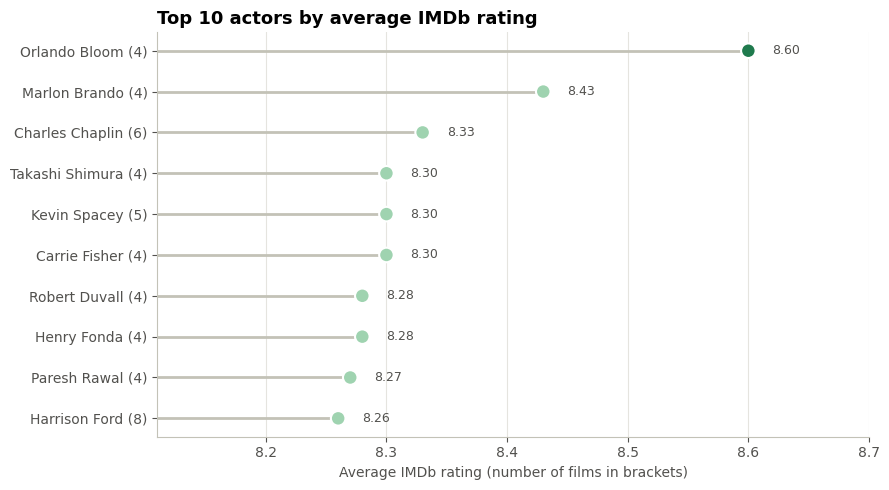

In [10]:
q3_actors = """
SELECT a.actor_name,
       COUNT(*)                     AS films,
       ROUND(AVG(r.imdb_rating), 2) AS avg_rating,
       ROUND(AVG(m.gross_revenue))  AS avg_gross
FROM actors a
JOIN movie_cast mc ON a.actor_id = mc.actor_id
JOIN movies m      ON mc.movie_id = m.movie_id
JOIN ratings r     ON m.movie_id = r.movie_id
GROUP BY a.actor_id, a.actor_name
HAVING COUNT(*) >= 4
ORDER BY avg_rating DESC
LIMIT 10
"""
actors = pd.read_sql(q3_actors, engine)
actors["label"] = actors["actor_name"] + " (" + actors["films"].astype(str) + ")"
dotplot(actors, "label", "avg_rating", "Top 10 actors by average IMDb rating",
     "Average IMDb rating (number of films in brackets)", fmt="{:.2f}")